# Example 9.1 — Droplet Trajectory Analysis

**Chapter 9: Step-by-Step Trajectory Synthesis**

This notebook generates the desired drop-shaped trajectory, implements the kinematic analysis of the four-bar mechanism using the Weierstrass solution, and evaluates the error for an initial design.

## 1. Import dependencies

In [14]:
import matplotlib.pyplot as plt
from numpy import *


## 2. Desired trajectory: drop-shaped curve

In [15]:
def trayectoria_gota(n=20):
    """Generates n points on the drop-shaped trajectory."""
    t = linspace(0, 2 * pi, n, endpoint=False)
    factor = 1 - 0.5 * sin(t / 2)
    xd = 100 + 50 * cos(t) * factor
    yd = 100 + 50 * sin(t) * factor
    return xd, yd

n_pts = 20
xd, yd = trayectoria_gota(n_pts)

print('Desired trajectory (first 5 points):')
print(f"{'i':>3}  {'xd':>8}  {'yd':>8}")
for i in range(5):
    print(f"{i:>3}  {xd[i]:>8.2f}  {yd[i]:>8.2f}")

Desired trajectory (first 5 points):
  i        xd        yd
  0    150.00    100.00
  1    143.83    114.24
  2    134.20    124.85
  3    122.72    131.27
  4    110.91    133.58


## 3. Kinematic analysis — Weierstrass solution

In [16]:
def analizar_mecanismo(r1, r2, r3, r4, theta2):
    """Calculates θ3 and θ4 for the given position of θ2."""
    A = 2 * r4 * (r1 - r2 * cos(theta2))
    B = -2 * r2 * r4 * sin(theta2)
    C = r1**2 + r2**2 + r4**2 - r3**2 - 2 * r1 * r2 * cos(theta2)

    d = A**2 + B**2 - C**2
    if d < 0:
        return None, None

    t4 = 2 * arctan2(-B + sqrt(d), A - C)
    t3 = arctan2(
        (r4 * sin(t4) - r2 * sin(theta2)) / r3,
        (r1 + r4 * cos(t4) - r2 * cos(theta2)) / r3
    )
    return t3, t4

## 4. Error evaluation for an initial design

In [17]:
r1, r2, r3, r4 = 80.0, 40.0, 100.0, 90.0
t2_vals = linspace(0, 2 * pi, n_pts, endpoint=False)
errores = []

for i in range(n_pts):
    t3, t4 = analizar_mecanismo(r1, r2, r3, r4, t2_vals[i])
    if t3 is not None:
        xa = r2 * cos(t2_vals[i]) + 30 * cos(t3) - 10 * sin(t3)
        ya = r2 * sin(t2_vals[i]) + 30 * sin(t3) + 10 * cos(t3)
        errores.append(sqrt((xa - xd[i])**2 + (ya - yd[i])**2))

print(f'r1={r1}, r2={r2}, r3={r3}, r4={r4} mm')
print(f'Mean trajectory error: {mean(errores):.4f} mm')
print(f'Maximum error:       {max(errores):.4f} mm')

r1=80.0, r2=40.0, r3=100.0, r4=90.0 mm
Mean trajectory error: 121.0127 mm
Maximum error:       132.5328 mm


## 5. Visualization

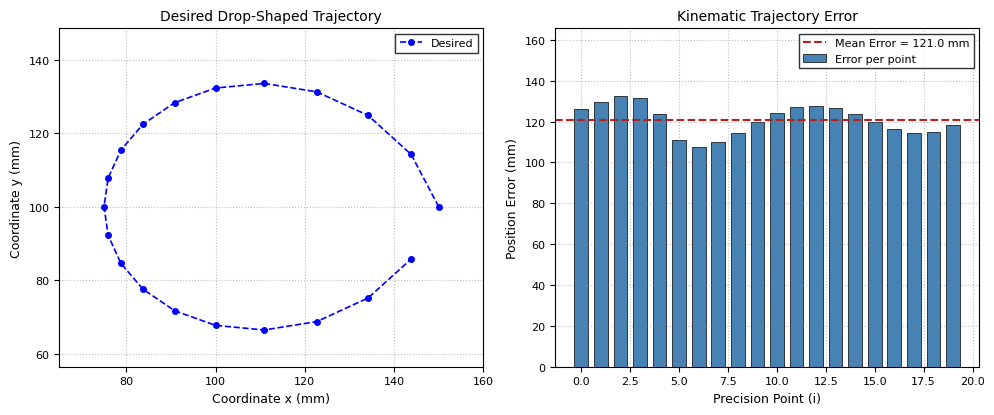

Figures successfully exported as 'ex9_1_drop_trajectory_analysis.pdf' and 'ex9_1_drop_trajectory_analysis.png' (600 DPI)


In [18]:
import os
import glob
import matplotlib.pyplot as plt
import numpy as np

# 1. Automated Filename Resolution
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex9_1_drop_trajectory_analysis"
except Exception:
    notebook_name = "ex9_1_drop_trajectory_analysis"

# 2. Global Springer Publication Typography Settings
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 8
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 8
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8

# 3. Figure Creation and Dimensions (Compact and balanced for Springer layout)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Subplot 1: Drop-Shaped Trajectory
axes[0].plot(xd, yd, 'b--o', ms=4, lw=1.2, label='Desired')
axes[0].set_title('Desired Drop-Shaped Trajectory')
axes[0].set_xlabel('Coordinate x (mm)')
axes[0].set_ylabel('Coordinate y (mm)')
axes[0].grid(True, linestyle=':', alpha=0.5, color='gray')
# Adjust limit to leave safe space for legends and avoid cuts
axes[0].set_xlim(min(xd) - 10, max(xd) + 10)
axes[0].set_ylim(min(yd) - 10, max(yd) + 15)
axes[0].legend(loc='upper right', frameon=True, fancybox=False, edgecolor='black')

# Subplot 2: Error per Precision Point
axes[1].bar(range(len(errores)), errores, color='steelblue', width=0.7, edgecolor='black', linewidth=0.5, label='Error per point')
axes[1].axhline(mean(errores), color='firebrick', ls='--', lw=1.5, label=f'Mean Error = {mean(errores):.1f} mm')
axes[1].set_title('Kinematic Trajectory Error')
axes[1].set_xlabel('Precision Point (i)')
axes[1].set_ylabel('Position Error (mm)')
axes[1].grid(True, linestyle=':', alpha=0.5, color='gray')
# Safe upper margin
axes[1].set_ylim(0, max(errores) * 1.25)
axes[1].legend(loc='upper right', frameon=True, fancybox=False, edgecolor='black')

plt.tight_layout()

# 4. Mandatory Double Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

print(f"Figures successfully exported as '{notebook_name}.pdf' and '{notebook_name}.png' (600 DPI)")